# Analisando Dados com Seaborn

Primeiro de tudo, vejamos como importar bases de dados do seaborn. Afinal, para aprender a utilizar os gráficos, precisamos de dados. O seaborn facilita nosso trabalho oferecendo alguns datasets nativos. Para saber o que temos à disposição, podemos chamar o método get_dataset_names do seaborn. Este método retornará uma lista com os nomes de todos os datasets que podemos importar.

In [67]:
import seaborn

datasets = seaborn.get_dataset_names()

datasets

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

Para importar um dataset, basta chamarmos o método load_dataset do seaborn passando como argumento o nome do dataset que queremos importar. O método retorna um dataframe do pandas. É importante ter familiaridade com o pandas antes de continuar com o seaborn.

In [68]:
penguins = seaborn.load_dataset("penguins")

penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## Distribuição e Densidade com Histograma

Um histograma é um gráfico capaz de demonstrar a distribuição de uma variável numérica contínua. No exemplo abaixo, utilizamos a base de dados de penguins como exemplo e plotamos um gráfico simples, definindo que a variável do eixo X será "body_mass_g" que no dataset representa o peso do pinguim.

O histograma tem o propósito de nos mostrar a densidade dos dados com base na variável numérica. Por isso, esse gráfico define o eixo Y como a contagem de registros de acordo com o eixo X. Observando o gráfico gerado, podemos perceber que há muitos penguins com peso de 3kg a 4kg em relação a outras faixas de peso como até 3kg ou com mais de 6kg.

Para exibir o gráfico, usamos a função show do matplotlib que é uma das bibliotecas que o seaborn utiliza por baixo dos panos. 

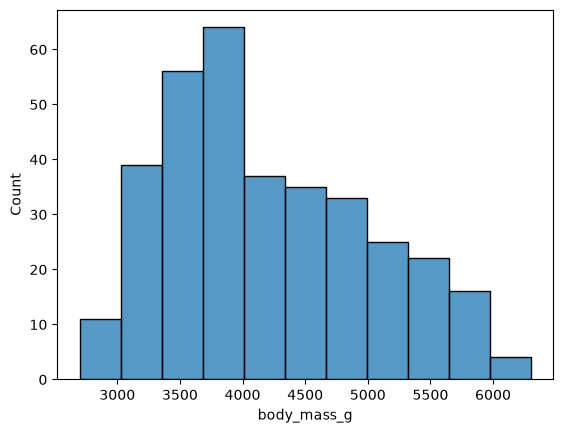

In [ ]:
import matplotlib.pyplot as pyplot

seaborn.histplot(
    data=penguins, 
    x="body_mass_g", 
)

pyplot.show()

No dataset há várias espécies de penguins e cada espécie naturalmente possui características diferentes, dentre elas, o peso. Para observar a distribuição do peso do animal considerando a espécie, podemos utilizar o parâmetro hue que receberá o nome da coluna de espécie. Para este gráfico, o hue tem de receber uma coluna categórica. Ou seja: com poucas opções de valores.

Com esse novo gráfico, conseguimos perceber claramente o motivo de haver um pico entre 3kg e 4kg. Esse pico ocorreu porque a maioria dos penguins da espécie Adelie tem entre 3kg e 4kg de peso corporal. Já as outras espécies têm menos penguins, penguis mais pesados ou com peso corporal mais uniformemente distribuído entre a população. Note como a espécie Gentoo tem uma curva muito mais sutil do que a espécie Adelie.

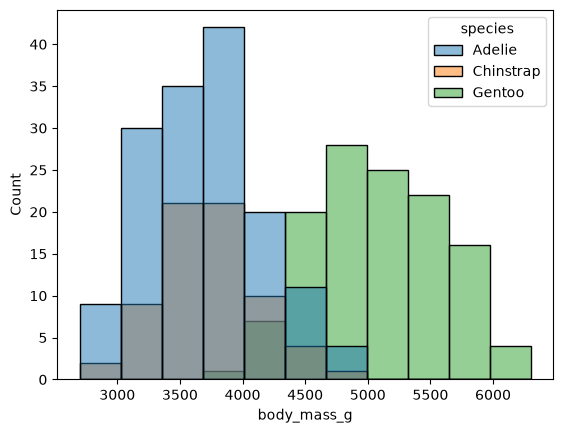

In [70]:
seaborn.histplot(
    data=penguins,
    x="body_mass_g",
    hue="species"
)

pyplot.show()

Outra coisa que podemos fazer é aumentar a quantidade de barras do gráfico. Isso vai ajudar a separar ainda mais os intervalos da variável contínua e identificar picos. Para fazer isso, utilizamos o parâmetro bins que receberá a quantidade de barras que queremos que o gráfico tenha. No gráfico gerado, ficou muito claro que há um pico na população de penguins da espécie Adelie com peso de 3,5kg. Quanto mais barras, melhor. Certo? Errado. É preciso dosar bem a quantidade de barras levando em consideração o intervalo da variável contínua e o número de registros. Uma quantidade maior de barras que o necessário exibirá muitos "picos" em intervalos pequenos e bases de dados pequenas.

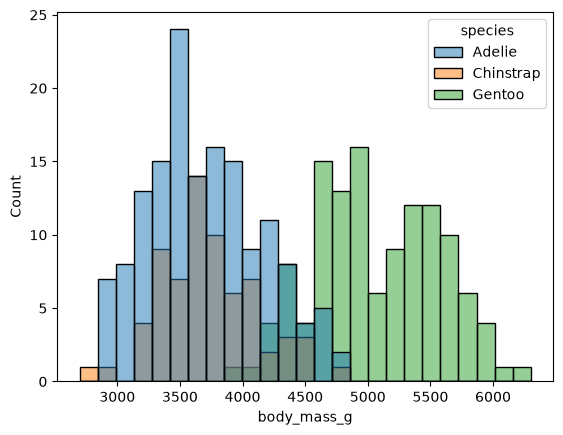

In [71]:
seaborn.histplot(
    data=penguins,
    x="body_mass_g",
    hue="species",
    bins=25,
)

pyplot.show()

Para melhorar ainda mais a visualização, podemos utilizar os argumentos kde e alpha. O argumento kde vai definir se o seaborn deve estimar uma linha KDE (Kernel Density Estimation). Em resumo, é como sobrepor um gráfico de linhas com um gráfico de barras. Habilitar a KDE pode ajudar a identificar populações distintas. Ou seja, com categorias diferentes. Para podermos perceber a utilidade da linha KDE, removemos o argumento hue. Perceba como a linha, assim como as barras, expõe um pico sutil nos 3,5kg. Isso pode indicar que a variável contínua sendo analisada é distribuída de forma diferente com base em alguma informação categórica.

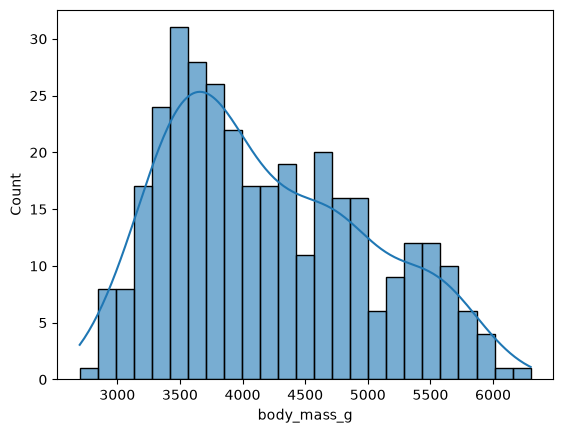

In [72]:
seaborn.histplot(
    data=penguins,
    x="body_mass_g",
    bins=25,
    kde=True,
    alpha=0.6
)

pyplot.show()

Quando utilizamos o hue, cada categoria é identificada por uma cor e a cor sofre uma mudança de opacidade para podermos observar as sobreposições de categorias. Por padrão, a opacidade das cores é de 0,5. Se quisermos modificar a opacidade, basta utilizar o parâmetro alpha que receberá a opacidade que desejamos que as cores tenham. Abaixo, observe como o gráfico ficou muito mais compreensível e portanto agregou muito mais valor a análise depois de melhorarmos ele com todas essas propriedades.

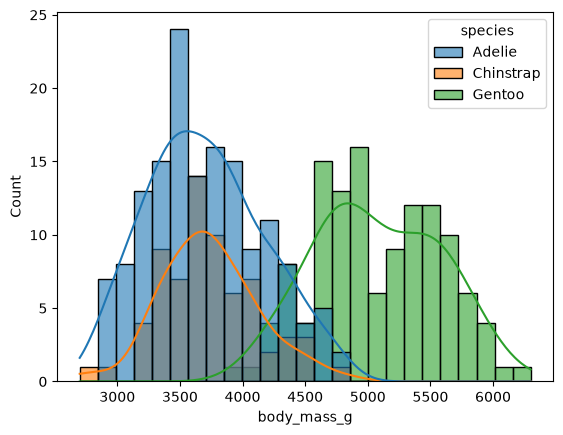

In [166]:
seaborn.histplot(
    data=penguins,
    x="body_mass_g",
    hue="species",
    bins=25,
    kde=True,
    alpha=0.6
)

pyplot.show()

Para finalizar com o histplot, podemos utilizar o pyplot para determinar o tamanho da figura utilizando o método figure do pyplot, passando um argumento figsize que recebe uma tupla de (largura, altura). O figsize é estimado em polegadas.

Também podemos utilizar métodos como o title, xlabel e ylabel para definir o título do gráfico, nome da métrica do eixo X e nome da métrica do eixo Y. 

Todas essas configurações devem ser feitas antes de chamar a função show do pyplot.

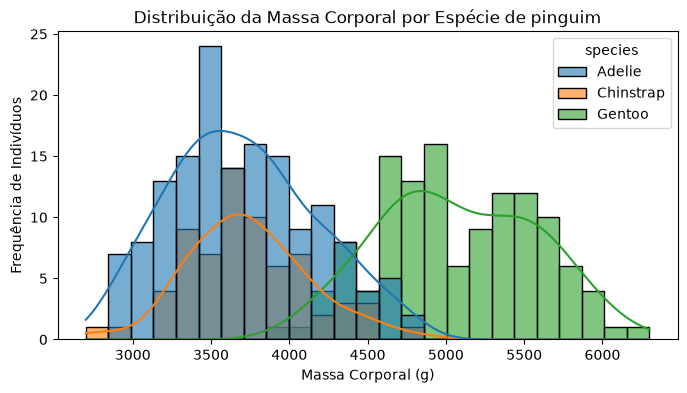

In [74]:
pyplot.figure(figsize=(8, 4))

seaborn.histplot(
    data=penguins,
    x="body_mass_g",
    hue="species",
    bins=25,
    kde=True,
    alpha=0.6
)

pyplot.title("Distribuição da Massa Corporal por Espécie de pinguim")
pyplot.xlabel("Massa Corporal (g)")
pyplot.ylabel("Frequência de Indivíduos")

pyplot.show()

**O que devemos extrair do gráfico?**

Quando o gráfico tiver formato de sino, significa que a variável analisada está em distribuição normal e que a média é muito similar à mediana. Isso indica que um modelo linear pode ser ideal. 

Agora, se o gráfico tiver um pico muito alto e os outros valores forem menos frequentes e muito maiores ou muito menores formando uma espécie de cauda, então a média deixa de ser confiável e a mediana deve ser priorizada. Nesse caso, modelos lineares dificilmente são apropriados a menos que se aplique transformação logarítmica, que normaliza a distribuição antes de treinar o modelo.

## Gráfico de Dispersão

Este é o gráfico de dispersão. Utilizamos ele quando queremos observar a correlação entre duas variáveis numéricas contínuas. No gráfico abaixo, utilizamos o dataset de tips (gorjetas) do seaborn. No eixo X configuramos a variável "total_bill" (valor total da conta). No eixo Y configuramos a variável "tip" (gorjeta). O que procuramos ao plotar esse gráfico é uma relação de proporcionalidade entre o valor gasto no restaurante e a gorjeta, esperando que quanto maior o valor gasto, maior a gorjeta. 

**Observando o gráfico, como sabemos se há correlação?**

Para determinar se há correlação entre as variáveis, basta olhar para a distribuição dos pontos no gráfico. Se os pontos estão muito espalhados e não formam um mínimo padrão visível, não há correlação. Se os pontos formam uma curva parabólica, há correlação, mas não é linear. Já quando os pontos formam uma reta que não se curva para cima e nem para baixo, há correlação, e é linear. Quando não há correlação linear, um algoritmo linear provavelmente não é uma boa escolha.

Outro ponto que podemos observar no gráfico é o efeito funil. Dizemos que há efeito funil quando o início da reta tem pouca variação entre os valores das variáveis e o final da reta tem muita variação. Note como os pontos estão muito mais juntos no início e muito mais separados no final. Para um valor total da conta até $10, a gorjeta quase sempre é de até $2. Já entre $40 e $50 de conta total, a gorjeta pode variar entre $3 até quase $10.

Mesmo com o gráfico em um estado muito simples, já conseguimos perceber que as duas variáveis tem uma certa correlação. Quando o X cresce e o Y cresce junto, dizemos que a correlação é positiva. Quando o X cresce e o Y diminui proporcionalmente, dizemos que a correlação é negativa. Neste caso, a correlação é positiva.



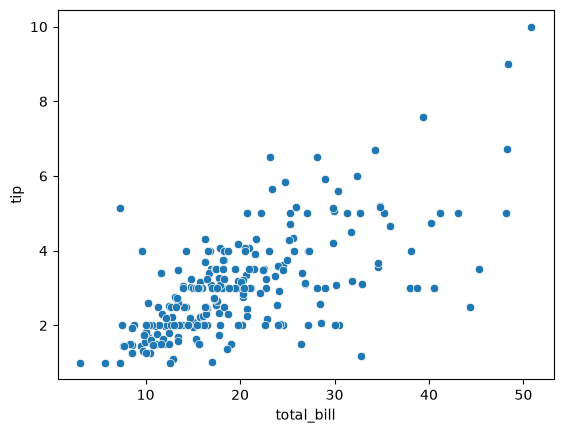

In [99]:
tips = seaborn.load_dataset("tips")

seaborn.scatterplot(
    data=tips,
    x="total_bill",
    y="tip"
)

pyplot.show()

Abaixo, atribuímos um valor ao parâmetro hue. Esse parâmetro é o nome da coluna do dataframe que representa o horário em que o indivíduo comeu no restaurante. Este horário está dividido entre "Lunch" (almoço) e "Dinner" (jantar). Essa configuração já nos revela outra informação. A maioria das contas no horário do almoço não ultrapassam os $25. Já para o jantar, uma boa parte das contas ultrapassam os $25. Indicando que geralmente os clientes gastam mais no jantar e que este é o horário em que o estabelecimento recebe gorjetas mais altas.

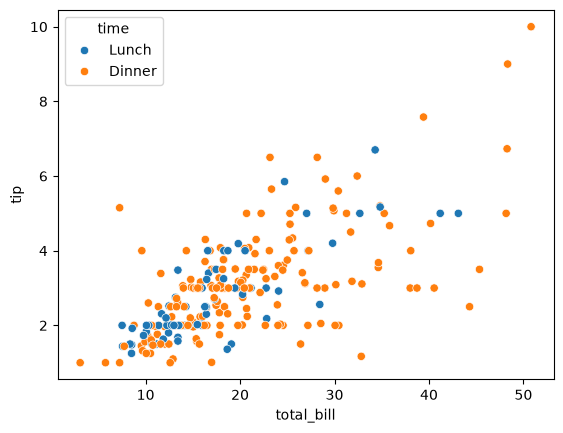

In [100]:
seaborn.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time"
)

pyplot.show()

O método scatterplot também pode receber um parâmetro size e outro parâmetro sizes. O parâmetro size receberá o nome de uma coluna do dataframe que deve ser uma variável numérica discreta. Ou seja: um número com poucas opções de valores. Para cada ponto no gráfico, o ponto será maior ou menor de acordo com o valor da variável numérica para aquele ponto. 

O seaborn calcula um valor mínimo e máximo para os pontos, mas, se você quiser outros valores, basta utilizar o parâmetro sizes. O parâmetro sizes deverá receber uma tupla com dois valores numéricos, o primeiro será o tamanho mínimo do ponto e o segundo será o tamanho máximo do ponto.

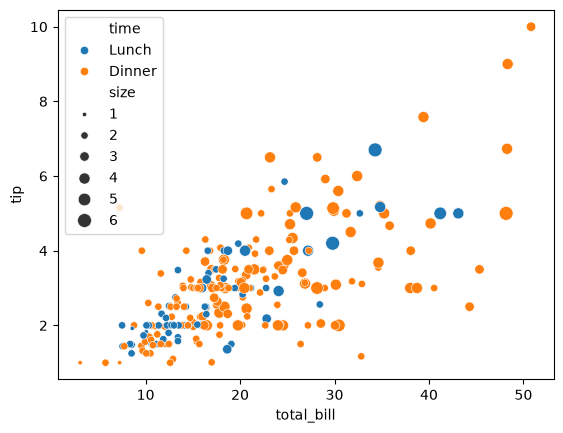

In [101]:
seaborn.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    size="size",
    sizes=(10, 100)
)

pyplot.show()

Por fim, podemos utilizar os parâmetros style e alpha. O parâmetro style mudará o formato dos pontos do gráfico de acordo com uma variável categórica. Na demonstração abaixo, utilizamos a coluna "smoker", que diz se o cliente era fumante ou não. Perceba que no geral, há muito mais não-fumantes do que fumantes e os não-fumantes geralmente pagam gorjetas mais altas, especialmente após os $20 de valor da conta total.

Como nesse caso utilizamos o hue, também podemos utilizar o parâmetro alpha que definirá a opacidade dos pontos do gráfico. Isso pode facilitar a leitura em gráficos muito populosos.

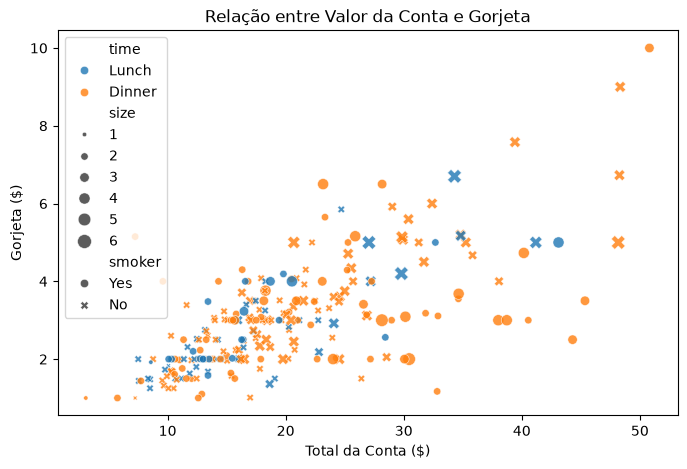

In [78]:
pyplot.figure(figsize=(8, 5))

seaborn.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    size="size",
    sizes=(10, 100),
    style="smoker",
    alpha=0.8
)

pyplot.title("Relação entre Valor da Conta e Gorjeta")
pyplot.xlabel("Total da Conta ($)")
pyplot.ylabel("Gorjeta ($)")

pyplot.show()

**O que devemos extrair do gráfico?**

Quando os pontos do gráfico estão muito dispersos, formam uma nuvem disforme/circular, dizemos que não há correlação. Quando formam uma linha em curva parabólica, dizemos que há correlação, mas não é linear. Quando os pontos do gráfico formam uma linha virtualmente reta, dizemos que há correlação, e é linear.

Se há correlação linear e o gráfico sobe da esquerda para a direta, dizemos que a correlação é positiva. Se o gráfico desce da esquerda para a direita, dizemos que a correlação é negativa.

Quando o gráfico tem forma de funil, sabemos que quanto mais alta for a variável X, maior é a incerteza para Y. Dessa forma, sabemos que um modelo linear clássico será muito penalizado nas métricas MSE e R2 Score. 

Procure por outliers. Outliers são pontos isolados no gráfico. Imagine por exemplo que um cliente cujo valor total da conta foi de $10 e deu uma gorjeta de $80. Esse cliente, no gráfico, estará no topo do gráfico, quase na extrema esquerda onde não existe ponto algum. Além disso, estará extremamente longe da nuvem de pontos. Visto que todos os pontos exceto por ele, têm gorjeta máxima de $10.

Outliers merecem investigação e podem provocar tanto uma decisão diferente para o treinamento do modelo como utilizar algoritmos que sofram menos com outliers como podem provocar um tratamento daquele dado em específico, pois pode estar incorreto, mal formatado, etc.

## Estatísticas Descritivas

### Gráfico de Caixa

O gráfico de caixa do seaborn representa visualmente algumas estatísticas sobre os dados. Este gráfico tem como finalidade comparar medianas, dispersão e anomalias entre diferentes grupos.

No exemplo abaixo, plotamos um gráfico de caixa para o dataframe de gorjetas tendo como eixo X o dia da semana e como eixo Y o valor total da conta. O gráfico de caixa vai montar 4 barras, uma para cada dia da semana. 

Cada barra terá características que nos dizem algo sobre o valor total da conta pelo dia da semana. As barras são divididas em 5 partes. Na parte colorida temos um traço horizontal dentro que representa a mediana ou segundo quartil (50% dos dados estão abaixo desta linha). A parte colorida abaixo do traço representa o primeiro quartil (25% dos dados estão abaixo desta linha). A parte colorida acima do traço representa o terceiro quartil (75% dos dados estão abaixo desta linha).

Já para os traços fora da parte colorida, temos uma pequena fórmula. 

IQR = Q3 - Q1

Sendo a subtração do terceiro quartil pelo primeiro quartil, o IQR contém os 50% centrais dos dados. 

Barra de limite superior: **Q3 + 1.5 * IQR** <br>
Barra de limite inferior: **Q1 - 1.5 * IQR**

Ou seja, as barras de limite superior e inferior NÃO representam os valores máximo e mínimo da variável para aquele dia da semana.

Observe que o gráfico também contém círculos acima e podem conter também abaixo de cada caixa. Esses círculos são para valores que superam as barras de limite. Eles são os outliers.

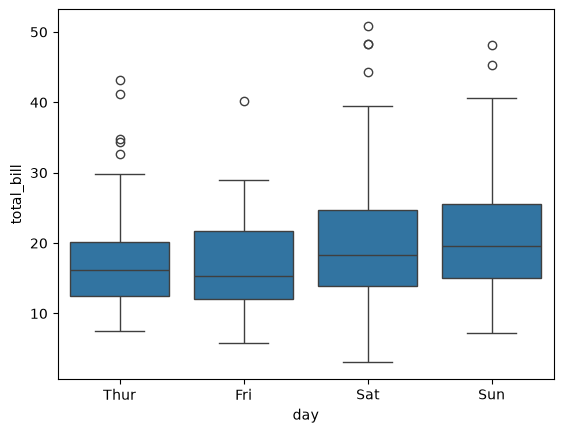

In [102]:
seaborn.boxplot(
    data=tips,
    x="day",
    y="total_bill"
)

pyplot.show()

Para o gráfico de caixa, também podemos especificar um argumento hue. Novamente, a coluna indicada no hue deverá ser uma coluna categórica ou numérica discreta. No exemplo, especificamos a coluna "sex" que representa o sexo do cliente. No gráfico, agora teremos duas caixas para cada dia da semana, calculando as métricas separadamente entre os sexos. Perceba que geralmente, nesse dataframe, as mulheres tem uma mediana mais baixa, limites inferiores e superiores mais baixos e quartis mais baixos. Além de outliers também mais baixos. Isso indica que homens geralmente pagam contas mais altas que as mulheres.

Podemos também utilizar um argumento palette que mudará a paleta de cores do gráfico.

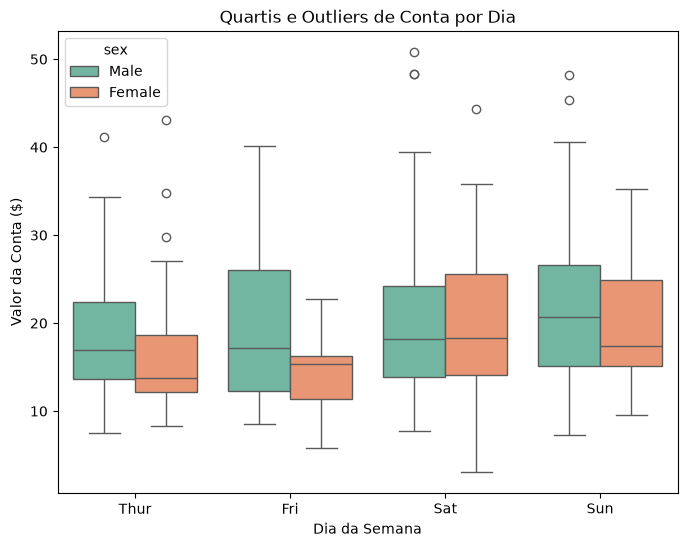

In [80]:
pyplot.figure(figsize=(8, 6))

seaborn.boxplot(
    data=tips,
    x="day",
    y="total_bill",
    hue="sex",
    palette="Set2"
)

pyplot.title("Quartis e Outliers de Conta por Dia")
pyplot.xlabel("Dia da Semana")
pyplot.ylabel("Valor da Conta ($)")

pyplot.show()

### Gráfico de Violino

O gráfico de violino tem essencialmente a mesma finalidade que o gráfico de caixa e é configurado quase exatamente da mesma forma. A única diferença é que o gráfico de violino não terá as seções em formato de barra, e sim seções curvadas. A curva representa a distribuição dos valores. Onde o formato de violino fica mais gordinho, há uma concentração maior daquele valor. Onde ele fica mais fino, há uma concentração menor. No gráfico abaixo, o dia de quinta-feira teve uma alta concentração de clientes pagando cerca de $15 no valor total da conta e uma baixa concentração de clientes pagando de $30 a $50.

Por vezes, o violino terá um formato irregular. Ou seja, no meio de um crescimento para os lados, poderá haver uma diminuição expressiva. Indicando que uma determinada faixa de valor pode ter alguma anomalia na distribuição.

Perceba que dentro da forma de violino temos a mesma estrutura do gráfico de caixa, contendo uma listra branca (mediana), os blocos dos quartis 1 e 3 e as linhas de IQR. Além disso, aqui também temos indicadores que o gráfico de caixa não tinha, que são os valores mínimo e máximo dos dados, representados pelas pontas do violino. Mas o gráfico não desenha as pontas de forma precisa o suficiente para que os limites sejam exatamente as pontas.

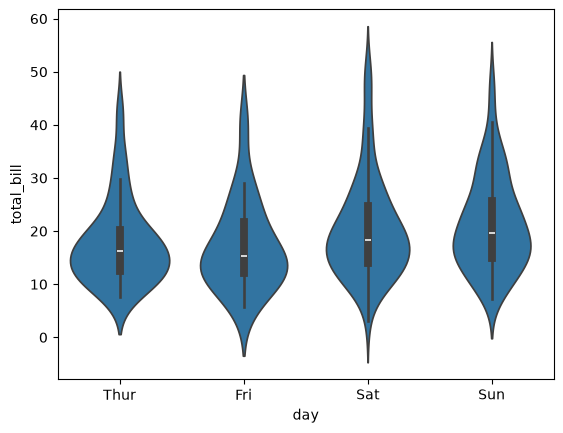

In [103]:
seaborn.violinplot(
    data=tips,
    x="day",
    y="total_bill",
)

pyplot.show()

Para que os limites dos violinos sejam exatamente os valores minímo e máximo, você pode utilizar o argumento cut. Esse argumento determinará se o desenho do violino deve ser cortado exatamente nos limites. Agora sim, as extremidades estão exatamente nos pontos mínimo e máximo.

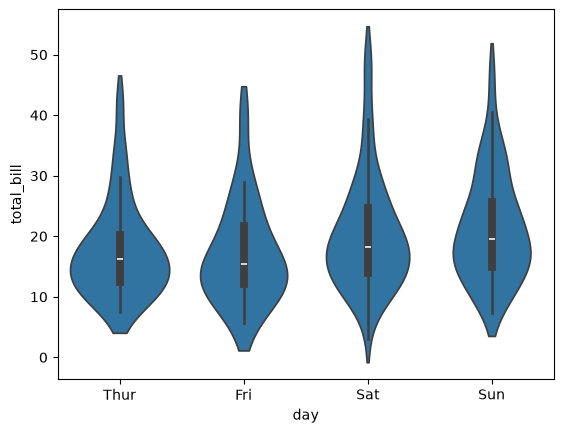

In [104]:
seaborn.violinplot(
    data=tips,
    x="day",
    y="total_bill",
    cut=True
)

pyplot.show()

Como de costume, podemos especificar uma coluna categórica para o argumento hue. Dessa forma, o gráfico exibirá dois violinos para cada dia da semana. No exemplo abaixo, separamos pelo sexo do cliente assim como no gráfico de caixa. Então serão desenhados um violino para os homens e um violino para as mulheres. Assim, conseguimos observar além de todas as outras métricas, a diferença na distribuição dos valores por categoria.

**AVISO**: O seaborn tem um bug na geração do gráfico de violino que faz com que colunas do dataframe do tipo CategoricalDtype tenham os dados invertidos. Ou seja, originalmente o seaborn montaria o gráfico trocando os dados de homens para as mulheres e vice-versa! Para resolver isso, é preciso transformar a coluna categórica em string antes de plotar o gráfico. A solução dada pode trocar a ordem das categorias na legenda. Para resolver esse outro ponto, podemos usar o argumento hue_order que recebe um array no qual vamos inserir todas as opções de valores para a coluna do argumento hue na ordem desejada.

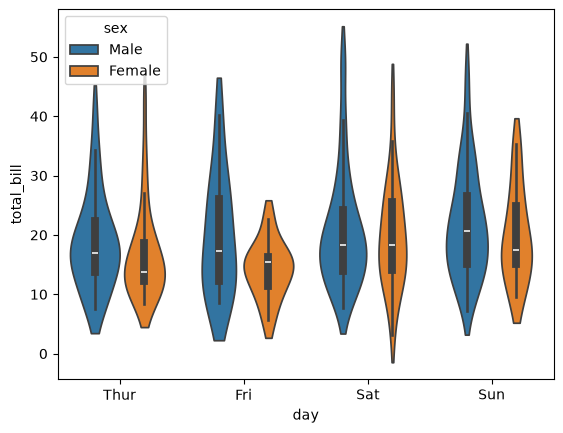

In [105]:
tips["sex"] = tips["sex"].astype(str)

seaborn.violinplot(
    data=tips,
    x="day",
    y="total_bill",
    cut=True,
    hue="sex",
    hue_order=["Male", "Female"]
)

pyplot.show()

Concorda que utilizando o hue, não ficou muito legível por ter tantos violinos? Para resolver isso, podemos especificar o argumento split. O split vai definir se cada violino será dividido ou não. Quando o violino for dividido, um lado dele desenhará as caixas e curvas de violino para uma categoria e do outro lado as caixas e curvas para a outra categoria. Assim, pode ficar mais fácil observar as diferenças.

Naturalmente, podemos definir uma proporção diferente para largura e altura da figura, paleta de cores diferente, título e legendas para os eixos X e Y utilizando funções do pyplot.

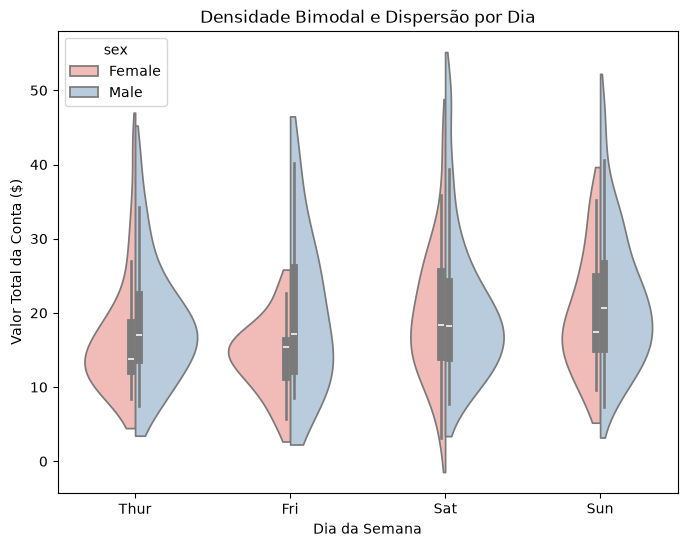

In [84]:
pyplot.figure(figsize=(8, 6))

seaborn.violinplot(
    data=tips,
    x="day",
    y="total_bill",
    cut=True,
    hue="sex",
    split=True,
    palette="Pastel1"
)

pyplot.title("Densidade Bimodal e Dispersão por Dia")
pyplot.xlabel("Dia da Semana")
pyplot.ylabel("Valor Total da Conta ($)")

pyplot.show()

## Agregações e Incerteza

### Gráfico de Contagem

O gráfico de contagem do seaborn vai fazer uma coisa muito simples. Exibir em forma de gráfico de barras a contagem de registros. No exemplo abaixo, usamos o dataframe de gorjetas e definimos o eixo X como a coluna "day" do dataframe. Na prática, o seaborn vai contar quantos registros cada dia da semana tem no dataframe e exibir essa informação em forma de gráfico de barra.

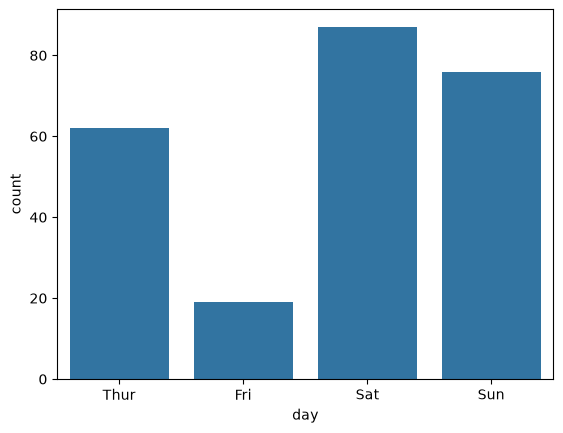

In [106]:
seaborn.countplot(
    data=tips,
    x="day"
)

pyplot.show()

Como de costume, podemos configurar um hue para o gráfico de contagem. No exemplo abaixo, definimos o sexo do cliente como hue. Assim, para cada dia o gráfico vai exibir duas barras, uma com a contagem de clientes do sexo masculino e outra com a contagem de clientes do sexo feminino. Lembrando: o hue tem de ser uma variável categórica ou numérica discreta.

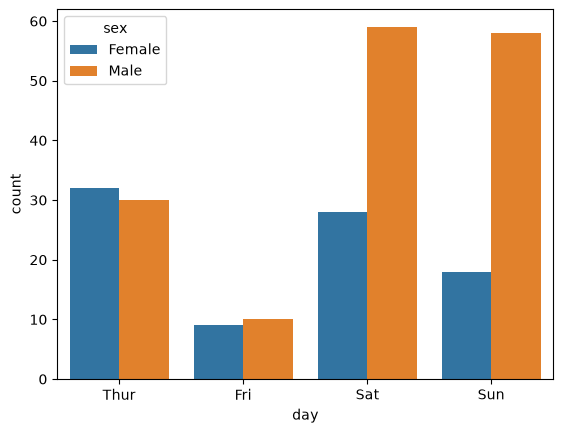

In [107]:
seaborn.countplot(
    data=tips,
    x="day",
    hue="sex"
)

pyplot.show()

Também podemos configurar outras coisas como a exibição da legenda com o argumento legend que definirá se a legenda será exibida ou não. Além de definir a ordem dos valores de X com o argumento order. O argumento order deve receber um array no qual inserimos os possíveis valores da variável do eixo X na ordem desejada. Por fim, também podemos definir uma proporção diferente para a figura, uma paleta de cores diferente, legendas para os eixos e um título para o gráfico.

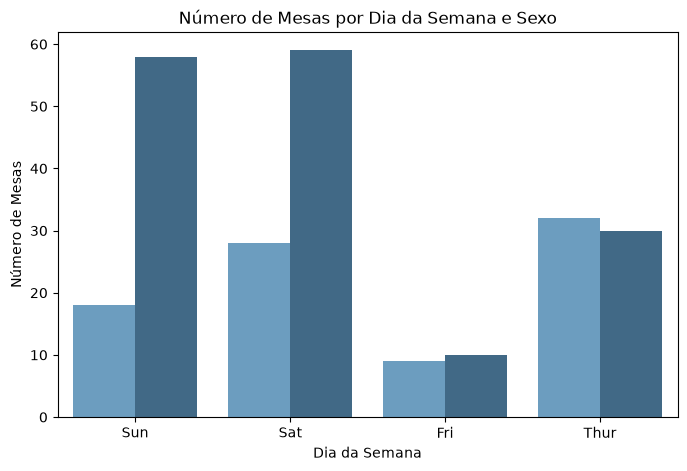

In [87]:
pyplot.figure(figsize=(8, 5))

seaborn.countplot(
    data=tips,
    x="day",
    hue="sex",
    legend=False,
    order=["Sun", "Sat", "Fri", "Thur"],
    palette="Blues_d"
)

pyplot.xlabel("Dia da Semana")
pyplot.ylabel("Número de Mesas")
pyplot.title("Número de Mesas por Dia da Semana e Sexo")

pyplot.show()

### Gráfico de Barra

No exemplo abaixo, plotamos um gráfico de barras utilizando o dataframe de gorjetas. Definimos o eixo X como o dia da semana e o eixo Y como o valor da gorjeta. Por padrão, o seaborn irá desenhar o gráfico indicando a média da variável do eixo Y. Então em resumo, nosso gráfico atualmente exibe a média de valor da gorjeta dos clientes por dia da semana.

Agora, você pode estar se perguntando: o que significam os tracinhos no topo de cada barra? Quando falamos de incerteza, o problema é o seguinte: Nosso dataframe tem algumas centenas de registros, mas, o restaurante pode atender milhares de mesas por mês. O que garante que a média ou a métrica calculada será sempre similar a atual? Absolutamente nada. Para diluir essa incerteza, o seaborn calcula a média várias vezes e em cada vez seleciona uma amostra diferente dos dados, chegando a vários resultados de médias. Naturalmente, os resultados formam um intervalo. Em algumas amostras a média da quinta-feira podem superar os $3 ou ficar abaixo dos $2,50 como o gráfico exibe. E é exatamente isso que os traços representam. O intervalo calculado dessa incerteza. Por padrão, o seaborn verifica apenas 95% dos casos. Ou seja, em 95% das amostras, o intervalo é o exibido pelo gráfico.

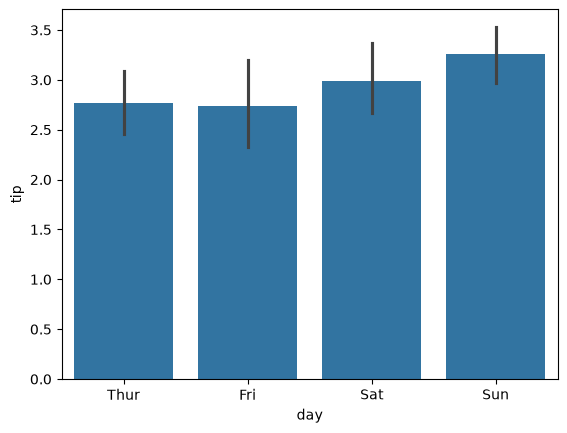

In [ ]:
seaborn.barplot(
    data=tips,
    x="day",
    y="tip"
)

pyplot.show()

Podemos configurar esse traço (barra de erro) utilizando o argumento errorbar que receberá uma tupla. O primeiro item deverá ser o método de cálculo e o segundo deverá ser a porcentagem de certeza. O método padrão de cálculo é o ci que significa em inglês "Confidence Interval" ou intervalo de confiança. 

Naturalmente, quanto mais certeza queremos ter, mais o intervalo deve crescer para garantir que o resultado real estará dentro do intervalo calculado. Então quanto maior for a certeza desejada, maiores serão os traços. Quando menor for a certeza desejada, menores serão os traços.

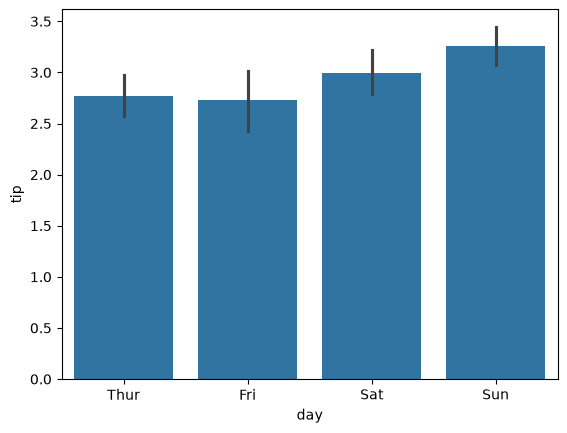

In [109]:
seaborn.barplot(
    data=tips,
    x="day",
    y="tip",
    errorbar=("ci", 80)
)

pyplot.show()

O método de cálculo da barra de erro também pode ser "sd" para Standard Deviation (Desvio Padrão) ou "se" para Standard Error (Erro padrão da Média). O argumento errorbar também pode receber None. Dessa forma, simplesmente não existe traço para barra de erro.

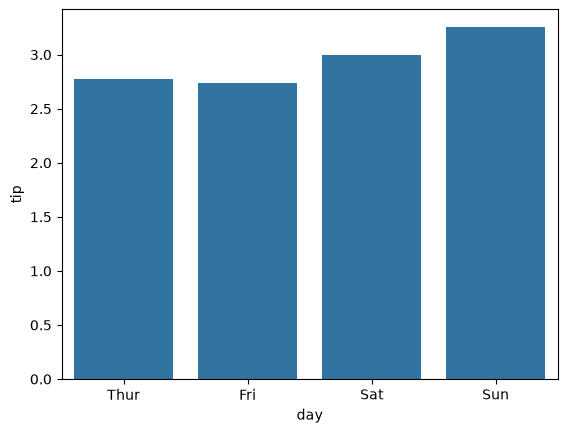

In [110]:
seaborn.barplot(
    data=tips,
    x="day",
    y="tip",
    errorbar=None
)

pyplot.show()

Como em todos os gráficos que vimos até agora, podemos configurar um hue. No exemplo abaixo, utilizamos o sexo do cliente como variável categórica. Na prática, o seaborn calcula duas barras separadamente para cada dia da semana.

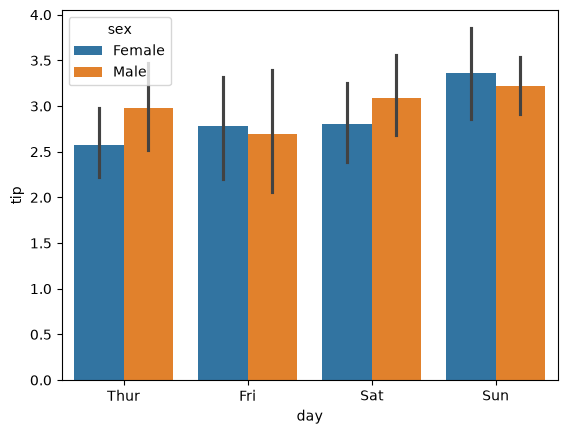

In [111]:
seaborn.barplot(
    data=tips,
    x="day",
    y="tip",
    errorbar=("ci", 95),
    hue="sex"
)

pyplot.show()

O gráfico de barras não calcula obrigatoriamente apenas a média. É possível passar um argumento estimator que pode receber valores como "median" para mediana, "mean" para média, "sum" para soma, "min" ou "max" para valores mínimos ou máximos, funções do numpy como numpy.std ou expressões lambda. Abaixo temos um exemplo com soma.

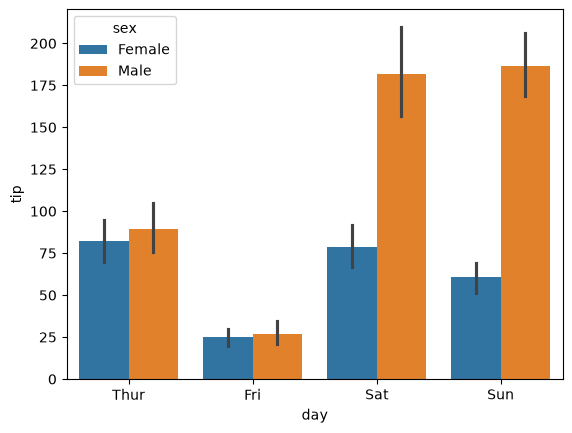

In [112]:
seaborn.barplot(
    data=tips,
    x="day",
    y="tip",
    errorbar=("ci", 95),
    hue="sex",
    estimator="sum"
)

pyplot.show()

Também podemos utilizar o argumento order para definir a ordem dos valores do eixo X. Podemos muito bem inverter a ordem, como no exemplo abaixo. Além de mudar a paleta de cores, definir uma proporção diferente para a figura, configurar as legendas dos eixos X e Y e atribuir um título ao gráfico.

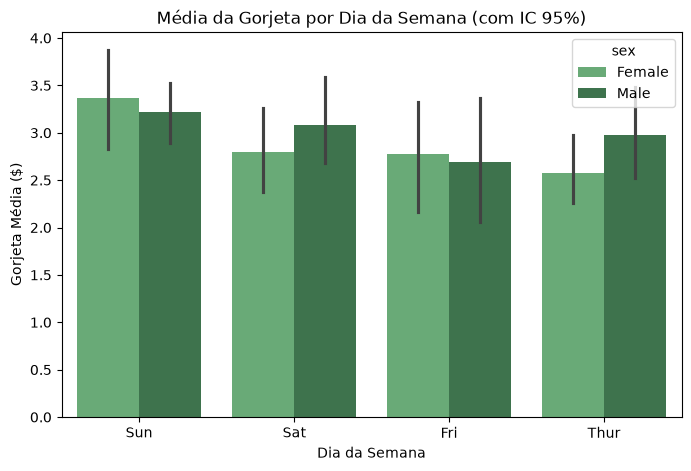

In [93]:
pyplot.figure(figsize=(8, 5))

seaborn.barplot(
    data=tips,
    x="day",
    y="tip",
    hue="sex",
    errorbar=("ci", 95),
    order=["Sun", "Sat", "Fri", "Thur"],
    palette="Greens_d"
)

pyplot.xlabel("Dia da Semana")
pyplot.ylabel("Gorjeta Média ($)")
pyplot.title("Média da Gorjeta por Dia da Semana (com IC 95%)")

pyplot.show()

## Séries Temporais e Tendências

Para analisar séries temporais, geralmente utilizamos gráficos de linha. Para gerar um gráfico de linha no seaborn, utilizamos o método lineplot que receberá um argumento data que deverá ser o dataframe, um argumento X e outro argumento Y que indicam as features nos eixos X e Y. O seaborn vai realizar uma agregação do dataframe de acordo com algum método. Por padrão é calculada a média. No exemplo abaixo, utilizamos o dataset de vôos do seaborn. Definimos como eixo X a coluna year e como eixo Y a coluna passengers. Na prática, o seaborn vai calcular a média de passageiros por vôo para cada ano e desenhar essa informação em forma de gráfico.

Observando o gráfico, podemos perceber que há uma área sombreada próxima à linha. Essa área cumpre exatamente o mesmo papel que o intervalo de confiança do gráfico de barra. O seaborn calcula a média de passageiros por ano várias vezes selecionando conjuntos diferentes de dados do dataset e com base nos resultados, plota o gráfico exibindo a linha real de média do dataset e o intervalo entre os resultados mínimo e máximo das médias calculadas.

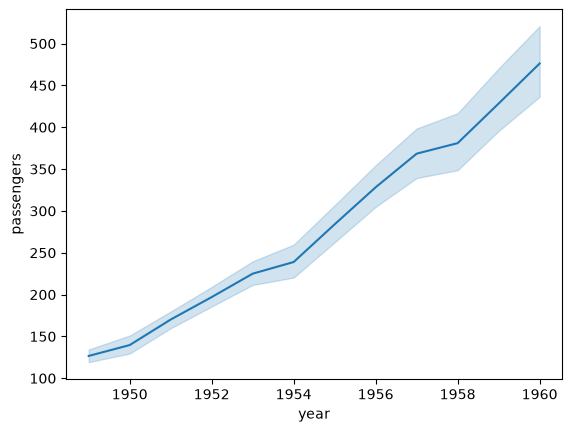

In [115]:
flights = seaborn.load_dataset("flights")

seaborn.lineplot(
    data=flights,
    x="year",
    y="passengers"
)

pyplot.show()

Podemos utilizar o argumento estimator para mudar o método de agregação dos dados. Abaixo, estamos utilizando "sum", que irá somar a quantidade de passageiros ao longo de todo o ano para cada ano.

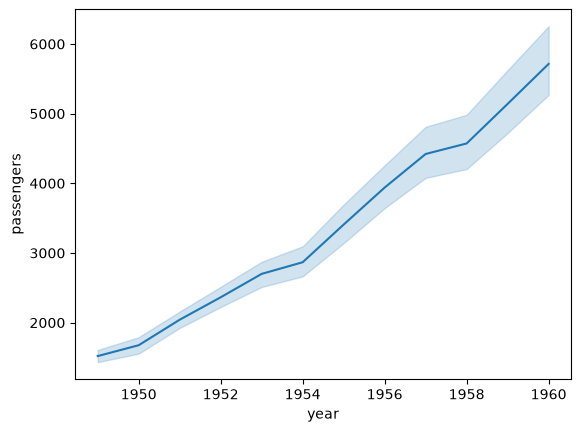

In [116]:
seaborn.lineplot(
    data=flights,
    x="year",
    y="passengers",
    estimator="sum"
)

pyplot.show()

No gráfico de linha, também podemos configurar a barra de erro utilizando o argumento errorbar assim como fizemos no gráfico de barras. O argumento deverá receber uma tupla na qual o primeiro item deve ser a estratégia de cálculo e o segundo item deverá ser a porcentagem de confiança desejada.

Relembrando, a estratégia de confiança poderá ser "ci" para Confidence Interval (intervalo de confiança), "se" para Standard Error (erro padrão), "sd" para Standard Deviation (desvio padrão) ou None para ocultar completamente a barra de erro.

Assim como no gráfico de barra, quanto maior for a confiança desejada, maior será o intervalo. Quanto menor for a confiança desejada, menor o intervalo.

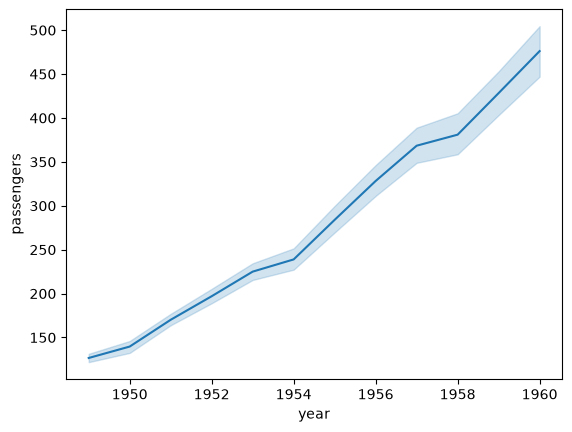

In [117]:
seaborn.lineplot(
    data=flights,
    x="year",
    y="passengers",
    errorbar=("ci", 80)
)

pyplot.show()

Neste gráfico, também podemos definir um hue. No exemplo abaixo, definimos o mês como hue. Na prática, o seaborn irá agregar os dados de acordo com a estratégia definida (padrão: média) para cada mês de cada ano separadamente, desenhando uma linha para cada mês. Quando não há mais de uma linha no dataframe com a mesma combinação entre o valor do eixo X e o hue, a barra de erro é desabilitada, já que não é possível calcular a métrica de várias formas diferentes. 

É recomendável aplicar o hue apenas para variáveis categóricas ou numéricas discretas com menos valores possíveis. Perceba que no gráfico de exemplo, a legibilidade não está a mais ideal pelo fato de termos 12 linhas no total. 

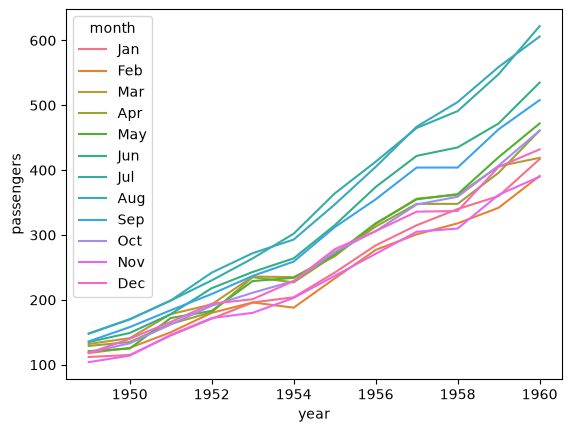

In [97]:
seaborn.lineplot(
    data=flights,
    x="year",
    y="passengers",
    estimator="sd",
    hue="month"
)

pyplot.show()

Para evidenciar melhor outras funcionalidades, utilizaremos o dataset fmri que contém medições de exames neurocientíficos de atividade cerebral. Abaixo, definimos que o eixo X recebe a coluna timepoint do dataframe que representa o tempo decorrido em segundos desde o início do teste. O eixo Y recebe a intensidade da atividade cerebral detectada. Como hue, utilizamos o event que é o tipo de teste aplicado no paciente.

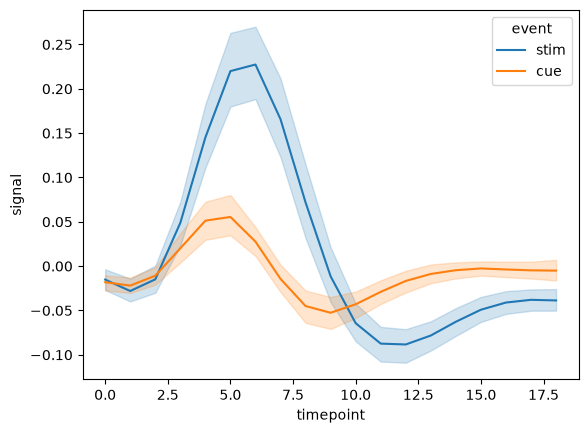

In [98]:
fmri = seaborn.load_dataset("fmri")

seaborn.lineplot(
    data=fmri,
    x="timepoint",
    y="signal",
    hue="event"
)

pyplot.show()

Além do hue, também podemos utilizar o argumento style. O argumento style, assim como o hue, deverá receber o nome de uma coluna categórica ou numérica discreta do dataframe. Para cada possível valor dessa coluna, o seaborn desenhará uma linha com estilo diferente. Abaixo, atribuímos o valor "region" para o argumento style. O "region" no dataframe de fmri se refere à região do cérebro. Agora, nosso gráfico desenha uma linha para a atividade cerebral por momento do teste para cada região do cérebro. Sendo parietal ou frontal. Note que a linha é desenhada de uma forma diferente. Nesse caso, a segunda linha tem estilo tracejado. Se quisermos que todas as linhas sejam desenhadas de forma contínua, basta utilizar o argumento dashes, atribuindo a ele o valor False.

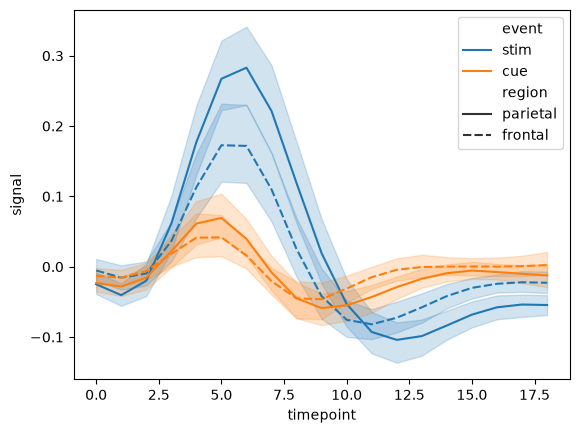

In [119]:
seaborn.lineplot(
    data=fmri,
    x="timepoint",
    y="signal",
    hue="event",
    style="region"
)

pyplot.show()

Por fim, podemos utilizar o argumento markers para definir se quisérmos que o seaborn desenhe pontos ou figuras onde de fato há dados concretos. Note que o gráfico é desenhado inserindo pontos nas interseções das colunas dos eixos X e Y e esses pontos posteriormente são ligados um ao outro, formando a linha. Os intervalos entre dois pontos consecutivos não contém dados concretos. 

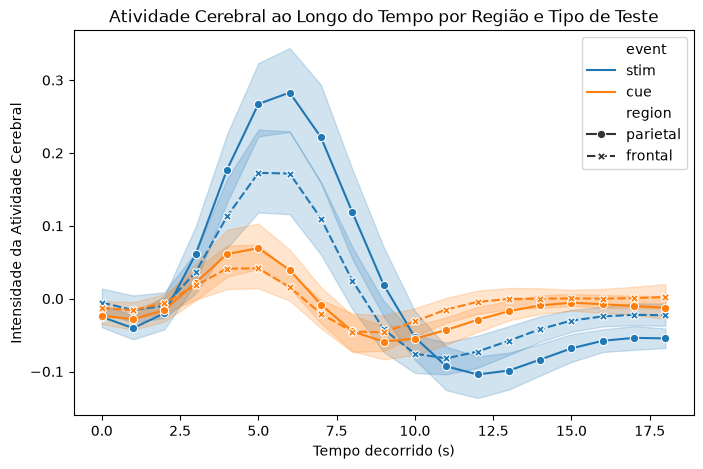

In [127]:
pyplot.figure(figsize=(8, 5))

seaborn.lineplot(
    data=fmri,
    x="timepoint",
    y="signal",
    hue="event",
    style="region",
    markers=True
)

pyplot.xlabel("Tempo decorrido (s)")
pyplot.ylabel("Intensidade da Atividade Cerebral")
pyplot.title("Atividade Cerebral ao Longo do Tempo por Região e Tipo de Teste")

pyplot.show()

**O que devemos extrair do gráfico?**

No gráfico, devemos procurar padrões de tendência, que é quando uma linha tem inclinação contínua de alta ou queda. Ou quando há pequenas altas e grandes quedas (tendência de queda), ou quando há grandes altas e pequenas quedas (tendência de alta).

Também podemos procurar por sazonalidades. Quando há oscilações repetidas em intervalos fixos. Como por exemplo se quisermos saber o volume de vendas de uma loja por mês do ano. É natural que em todo ano, nos meses finais tenha uma alta no volume de vendas. Outro exemplo poderia ser um restaurante se analisarmos a quantidade de clientes pelo horário do dia. Nesse caso, provavelmente observaríamos altas nos horários de almoço e de jantar.

Além disso, também podemos procurar por mudanças de regime. As mudanças de regime são quedas ou altas abruptas que ocorrem após uma determinada data. Se uma loja lançar um novo produto com uma promoção muito atraente, provavelmente haveria uma alta abrupta no volume de vendas. Ou se analisarmos aspectos econômicos após uma pandemia, nesse caso observaríamos por exemplo uma alta abrupta nos preços de vários insumos ou uma alta nas taxas de impostos.

## Matriz de Correlação

O seaborn disponibiliza um gráfico de matriz de correlação em formato de heatmap. Esse gráfico desenhará uma matriz analisando a proporção da correlação entre todas as combinações possíveis de duas variáveis. Supondo que um dataframe tenha quatro colunas numéricas, a matriz terá 4 x 4 = 16 blocos. Cada bloco representará numericamente o quanto o valor de uma coluna cresce ou diminui conforme a outra cresce ou diminui. É como plotar vários gráficos de dispersão, mas, resumindo cada um a uma cor e número.

Para gerar um gráfico de heatmap, primeiro temos de transformar nosso dataframe em um dataframe que contenha apenas colunas numéricas. Para isso, utilizamos o método select_dtypes do dataframe, incluindo apenas números pelo argumento include. Depois, precisamos gerar a matriz numérica de correlações. Para isso, utilizamos o método corr do dataframe. Esse método pode receber um argumento method que define o tipo de correlação. Por padrão, a correlação utilizada é a correlação de Pearson. Por fim, para plotar o gráfico, basta utilizar o método heatmap do seaborn passando a matriz numérica de correlação como valor para o argumento data.

O resultado é uma matriz de correlação que calcula a correlação entre cada variável e cada uma de todas as outras. A cor de cada bloco representa a proporção da correlação entre as duas variáveis referentes ao bloco.

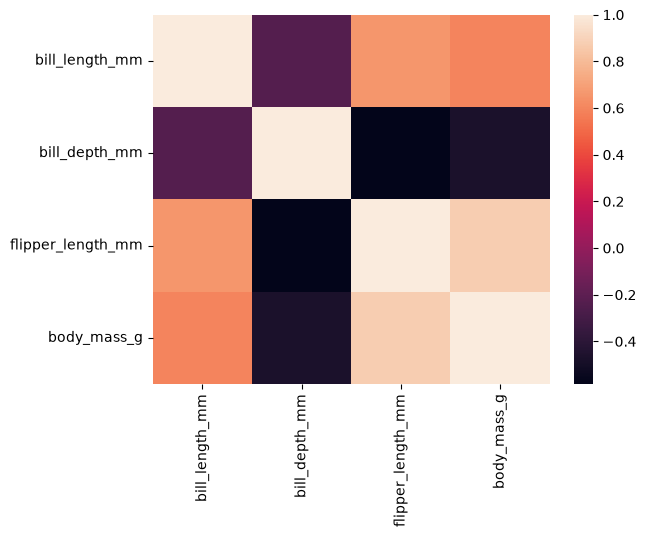

In [140]:
penguins_numeric = penguins.select_dtypes(include="number")
penguins_correlations = penguins_numeric.corr(method="pearson")

seaborn.heatmap(
    data=penguins_correlations
)

pyplot.show()

É muito útil sabermos o valor exato da correlação entre as variáveis, pois na análise, comumente temos de escolher entre uma correlação e outra. Convém escolher a correlação com maior valor absoluto. Para exibir a proporção de cada correlação, utilizamos o argumento annot que define se o número será exibido ou não.

<Axes: >

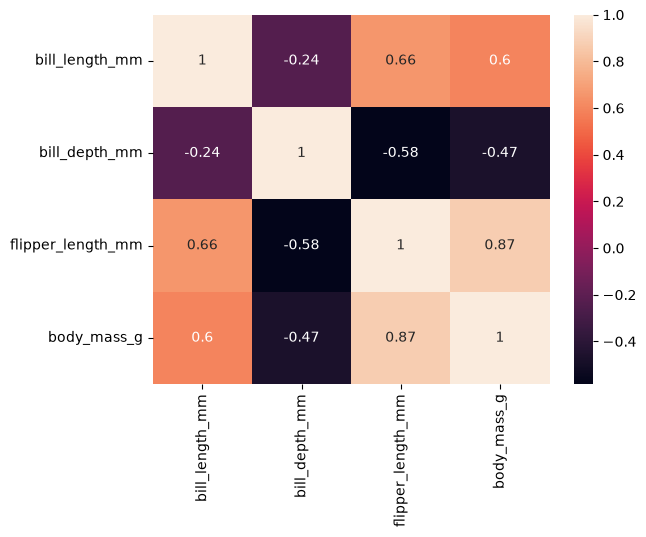

In [ ]:
seaborn.heatmap(
    data=penguins_correlations,
    annot=True
)

pyplot.show()

No nosso exemplo, não aconteceu. Mas é comum que os números de cada correlação tenham muitas casas decimais, dificultando muito a legibilidade. Para solucionar esse problema, podemos utilizar o argumento fmt que deve receber uma anotação capaz de formatar o número assim como fazemos quando queremos limitar as casas decimais em um print regular. No exemplo abaixo, limitamos a duas casas decimais.

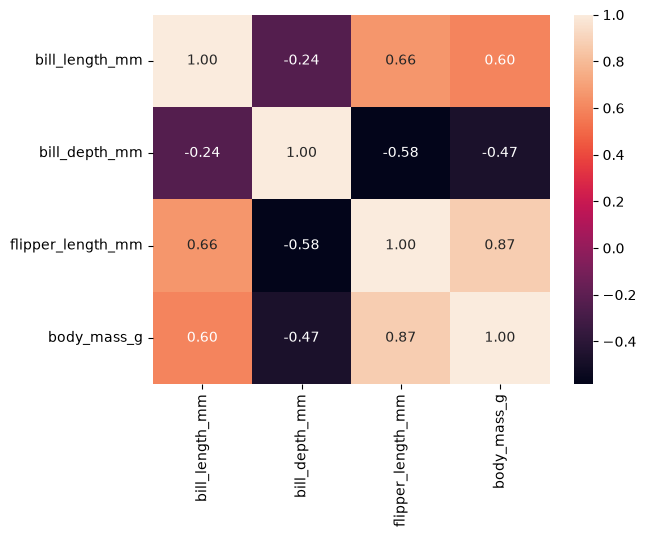

In [142]:
seaborn.heatmap(
    data=penguins_correlations,
    annot=True,
    fmt=".2f"
)

pyplot.show()

Dois outros argumentos muito úteis são vmin e vmax. Eles definem os valores mínimo e máximo, respectivamente, que deverão representar as correlações de cada bloco. No exemplo abaixo, limitamos esse número a estar entre -1 e 1.

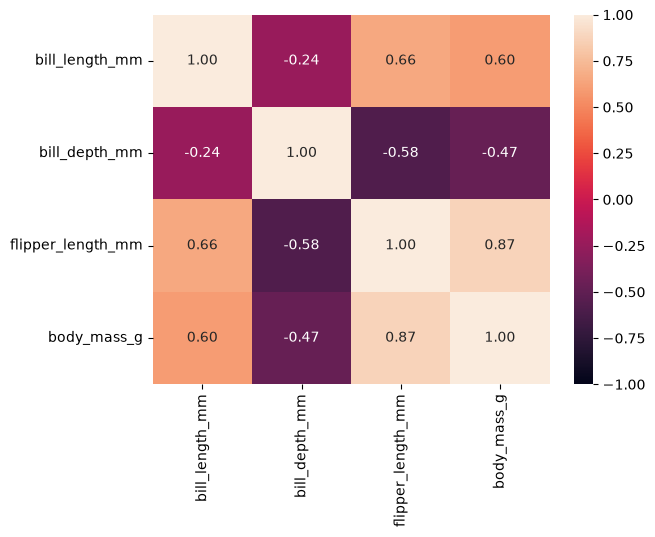

In [143]:
seaborn.heatmap(
    data=penguins_correlations,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1
)

pyplot.show()

Para que o gráfico fique ainda mais intuitivo, podemos mudar a paleta de cores usando o argumento cmap. Na paleta de cores coolwarm, as cores variam de vermelho até branco e finalmente azul. Quanto mais perto do valor máximo, mais vermelho. Quanto mais perto de 0, mais branco. E quanto mais perto do valor mínimo, mais azul.

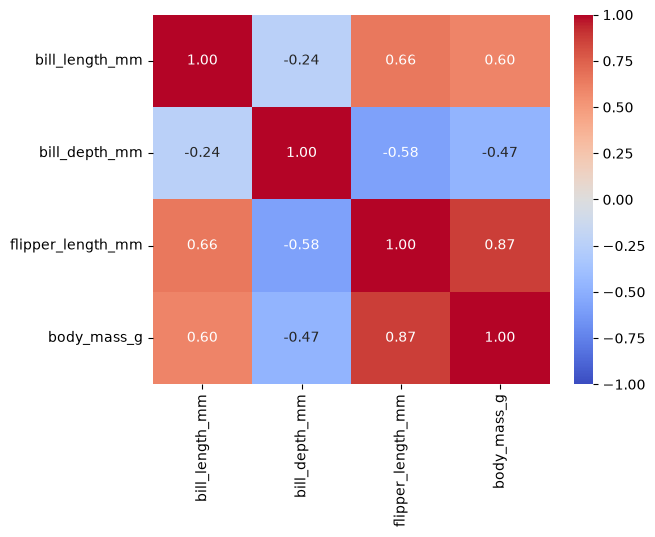

In [150]:
seaborn.heatmap(
    data=penguins_correlations,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

pyplot.show()

Podemos utilizar o argumento cbar_kws para definir uma legenda para a escala de coeficiente. Como no exemplo abaixo. Além de definir um título para o gráfico usando o pyplot.

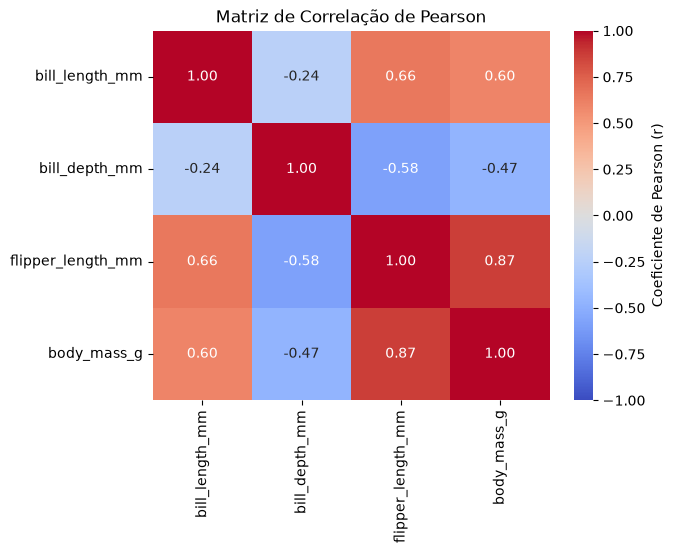

In [152]:
seaborn.heatmap(
    data=penguins_correlations,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    cbar_kws={ "label": "Coeficiente de Pearson (r)" }
)

pyplot.title('Matriz de Correlação de Pearson')

pyplot.show()

**O que devemos extrair do gráfico?**

Quando o coeficiente for igual a 1 em um bloco, significa que ambas as colunas crescem de forma perfeitamente proporcional. É uma correlação linear positiva perfeita. Quando o coeficiente é 0, não há nenhuma correlação linear detectável. Quando o coeficiente é -1, uma coluna aumenta e a outra diminui de forma perfeitamente proporcional. É uma correlação linear negativa perfeita.

Ao ler o gráfico, desprezamos completamente a diagonal que tem apenas coeficientes de valor 1. É nesses pontos que cada coluna cruza com si própria.

Imagine que duas variáveis tem uma correlação muito alta entre si (ex: 0.85 ou -0.85). Isso significa que as duas colunas do dataframe dizem essencialmente a mesma coisa. Idealmente uma delas deverá ser descartada ou tratada por técnicas de regularização. É recomendável que se mantenha que tiver a maior correlação absoluta com a variável que queremos predizer (ex: escolher -0.88 ao invés de 0.83)

Note que correlação e causalidade são duas coisas diferentes. Matematicamente a venda de sorvetes e o número de mortes por afogamento podem ter um coeficiente de correlação de 0.92. Mas, o sorvete não causa morte por afogamento. Então, essa correlação é absolutamente inútil.

## Distribuição e Dispersão Combinada

Suponha que você tem um problema de classificação e tem nas mãos diversas variáveis numéricas. Pode ser de muita utilidade plotar um pairplot. O que esse gráfico faz é combinar dois tipos de gráficos diferentes: o gráfico de dispersão e o histograma. Assim como o heatmap, ele gera uma matriz, mas não uma matriz de blocos coloridos, e sim uma matriz de mais gráficos. Se tivermos 4 variáveis numéricas, teremos 4 x 4 = 16 gráficos. Os gráficos de dispersão são gerados para cada combinação de duas variáveis exceto quando ela combina com si própria. Dessa forma, conseguimos observar a relação de todas as variáveis com todas as outras variáveis em gráficos de dispersão.

Nos blocos em que a variável colide com ela própria, não haverá um gráfico de dispersão, e sim um histplot que terá como eixo X a coluna respectiva.

Abaixo, fizemos um exemplo do gráfico combinado no dataset de pinguims. É ideal que no dataset passado como argumento tenhamos única e absolutamente apenas os dados numéricos que queremos analisar, pois o seaborn combina absolutamente todos eles, então se houver alguma variável que não precisa ser combinada e que seja numérica como por exemplo um identificador de usuário, o seaborn incluirá gráficos para essa variável. Outra prática ideal é que essas colunas numéricas não tenham absolutamente nenhum valor nulo para garantir que todos os gráficos da matriz utilizem exatamente os mesmos dados. Afinal, há gráficos que consideram valores nulos (ex: na média, divide por 344 mesmo se houver apenas 342 valores não nulos) e há gráficos que não consideram.

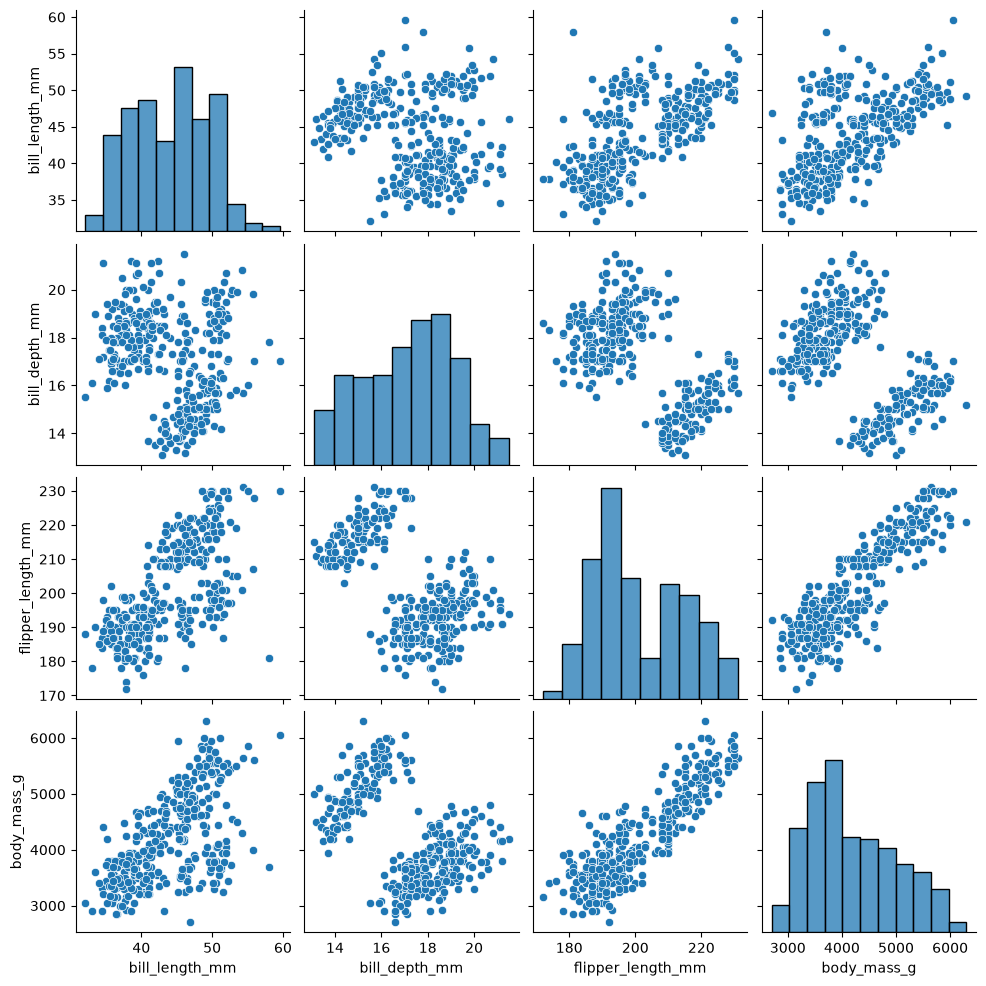

In [ ]:
seaborn.pairplot(
    data=penguins.dropna()
)

pyplot.show()

Para o gráfico combinado, também podemos especificar um hue. Geralmente, o hue é a variável categórica que queremos predizer. Nesse caso, suponha que queremos predizer a espécie de um pinguim. Alguns dos gráficos de dispersão têm certas espécies quase completamente separadas umas das outras. Perceba também que há pelo menos uma ocorrência de cada espécie que está separada das outras. Esse é um sinal muito forte de que um algoritmo baseado em árvore de decisão pode ser o mais ideal e ter uma acurácia muito boa.

Observe os gráficos de histograma. Percebe que neles, algumas vezes ocorre que uma espécie de pinguim está quase totalmente separada das outras espécies? Essa é outra forma de identificar o sinal favorável à algoritmos baseados em árvore de decisão.

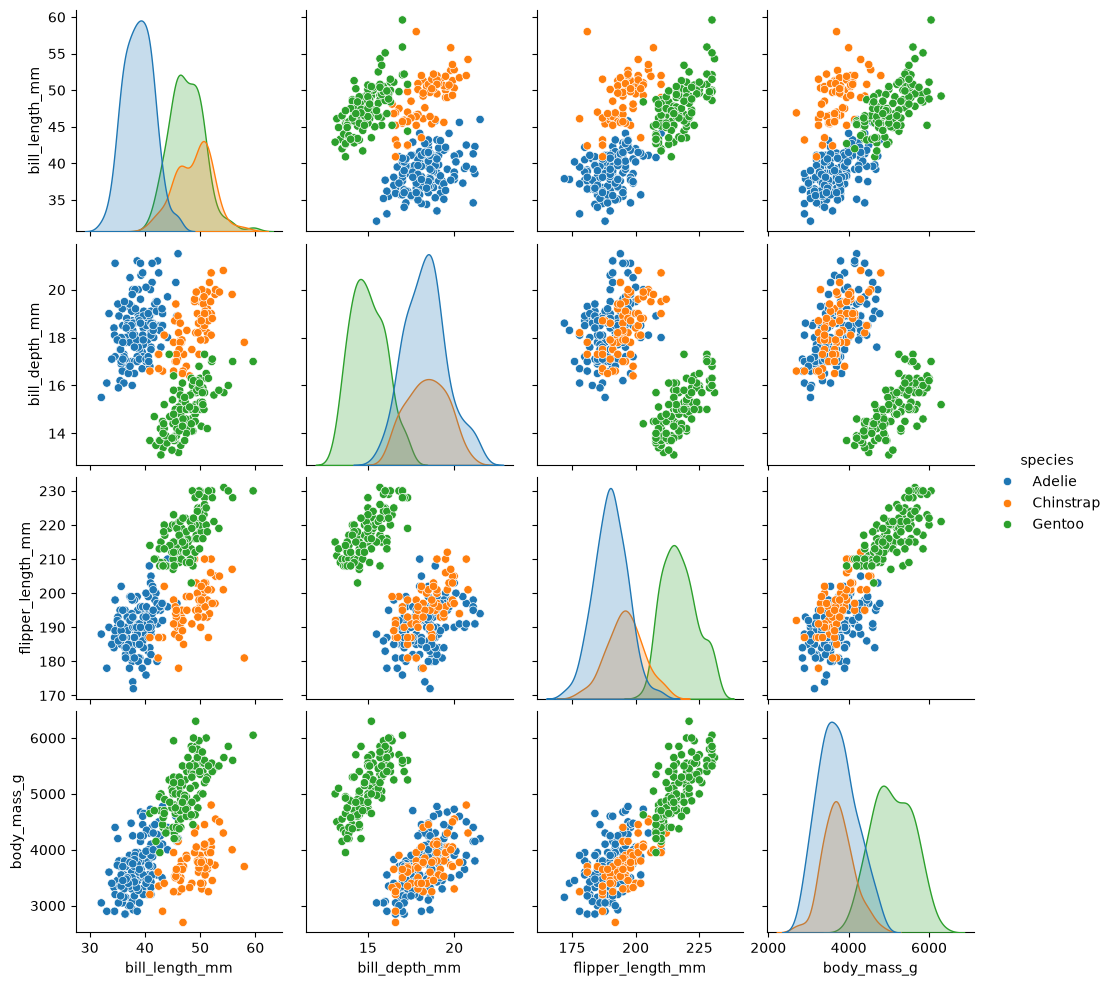

In [ ]:
seaborn.pairplot(
    data=penguins.dropna(),
    hue="species"
)

pyplot.show()

Se você parar para observar, vai perceber que os gráficos de dispersão do outro lado da diagonal são exatamente iguais aos do primeiro lado. Isso é uma característica universal de matrizes que cruzam o mesmo conjunto de dados (nesse caso, colunas). É possível ocultar os gráficos espelhados utilizando o argumento corner. Esse argumento definirá se os gráficos repetidos serão ocultados ou não.

Além disso, como sempre, podemos mudar a paleta de cores, definir um título para o gráfico. Por vezes não é útil adicionar legendas para os eixos X e Y, visto que o lado e a altura da matriz contém várias variáveis, e não uma única.

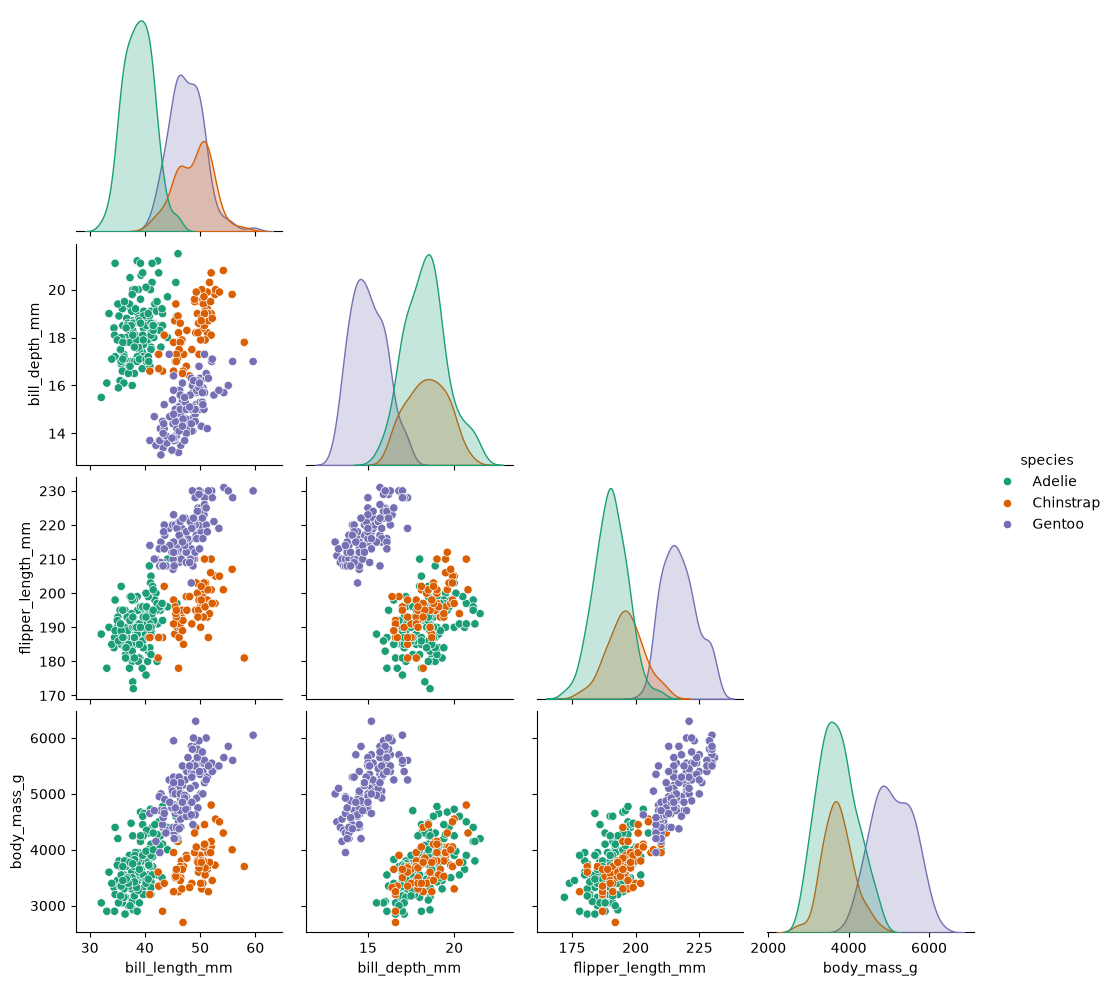

In [171]:
seaborn.pairplot(
    data=penguins.dropna(),
    hue="species",
    corner=True,
    palette="Dark2"
)

pyplot.show()